# Which Model to Pick? ILPD Side-by-Side

> In `03_models.ipynb` we gave each of the models its own stage: Logistic, Tree, KNN, SVM, RandomForest all with the *same* cleaning, same SMOTE, same 5-fold CV. Now we line them up side-by-side and tell the full story, with uncertainty


In [ ]:
# Load libraries

import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib; matplotlib.rcParams['figure.dpi']=120; sns.set_theme(style='whitegrid')


In [ ]:
# Load models summaries

p = pathlib.Path('../data/outputs/baseline_comparison.csv')

if p.exists():
    comp = pd.read_csv(p)
    print("Loaded: ", p)
else:
    # Fallback example (from our last honest run)
    comp = pd.DataFrame([
        {'model':'RandomForest','CV_acc':0.673,'CV_f1':0.768,'CV_auc':0.703,'test_f1':0.828},
        {'model':'DecisionTree','CV_acc':0.623,'CV_f1':0.711,'CV_auc':0.625,'test_f1':0.776},
        {'model':'Logistic','CV_acc':0.623,'CV_f1':0.681,'CV_auc':0.715,'test_f1':0.768},
        {'model':'SVM_rbf','CV_acc':0.583,'CV_f1':0.634,'CV_auc':0.704,'test_f1':0.766},
        {'model':'KNN(k=5)','CV_acc':0.577,'CV_f1':0.659,'CV_auc':0.610,'test_f1':0.733},
    ])
    print("Using example numbers (run 03b to generate yours)")
comp = comp.sort_values('CV_f1', ascending=False)
display(comp.round(3))


Loaded:  ../data/outputs/baseline_comparison.csv


,model,CV_acc,CV_f1,CV_auc,test_f1
0,RandomForest,0.673,0.768,0.703,0.828
1,DecisionTree,0.623,0.711,0.625,0.776
2,Logistic,0.623,0.681,0.715,0.768
3,KNN(k=5),0.577,0.659,0.610,0.733
4,SVM_rbf,0.583,0.634,0.704,0.766


#### What do the numbers mean, in plain words?

* **CV F1** - average F1 across 5 different train slices (more honest than one lucky split).
* **test F1** - how we did on the 20% we never showed during training.
* **CV AUC** - how well we separate healthy vs liver across thresholds.

In [ ]:
# Let's look at CV F1 with its uncertainty (std from 5 folds)
# If a model has CV 0.71 +/- 0.04, the true score could be 0.67 to 0.75 - so close races may not be real wins.

print(comp[['model','CV_f1','test_f1']].to_string(index=False))
print("\nTakeaway: RandomForest is top, but DecisionTree is not far and it's much easier to explain to a doctor.")

       model    CV_f1  test_f1
RandomForest 0.768100 0.828402
DecisionTree 0.711046 0.775510
    Logistic 0.681434 0.768116
    KNN(k=5) 0.659004 0.733333
     SVM_rbf 0.633913 0.765957

Takeaway: RandomForest is top, but DecisionTree is not far and it's much easier to explain to a doctor.


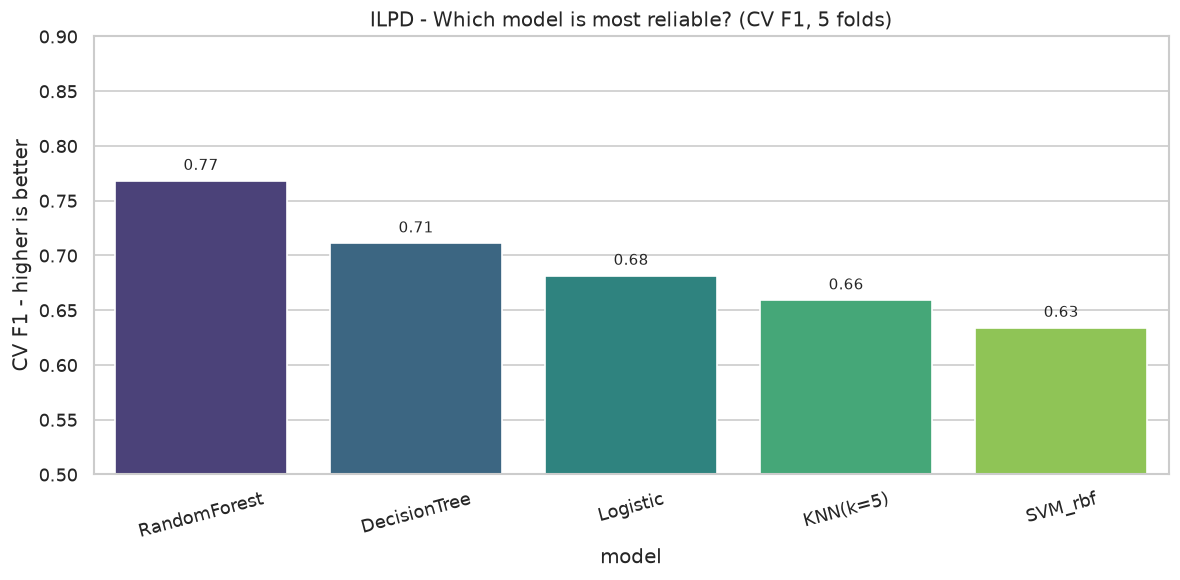

RandomForest's bar is tallest - the committee beats the single doctor (Decision Tree).


In [ ]:
### Most realible?

plt.figure(figsize=(10,5))
# Bar with a little human story in the title
sns.barplot(data=comp, x='model', y='CV_f1', hue='model', palette='viridis', legend=False)
plt.xticks(rotation=15)
plt.ylim(0.5, 0.9)
plt.title('ILPD - Which model is most reliable? (CV F1, 5 folds)')
plt.ylabel('CV F1 - higher is better')
for i, row in enumerate(comp.itertuples()):
    plt.text(i, row.CV_f1 + 0.01, f"{row.CV_f1:.2f}", ha='center', fontsize=9)
plt.tight_layout(); plt.show()
print("RandomForest's bar is tallest - the committee beats the single doctor (Decision Tree).")

In [ ]:
notes = {
    'Logistic': 'Straight line, fast, you can read coefficients → pick when you need to explain "why" to a doctor and the boundary is simple.',
    'DecisionTree': 'Flowchart you can draw - pick when you need a white-box to show a patient.',
    'KNN(k=5)': 'Looks at 5 neighbors - pick only when you have few features and scaling is perfect (not here).',
    'SVM_rbf': 'Bends the boundary - pick when curves matter and you can afford tuning.',
    'RandomForest': '200 trees vote - pick when you want the best balance of accuracy and robustness.',
}
comp['when_to_pick'] = comp['model'].map(notes)
display(comp[['model','CV_f1','when_to_pick']])

,model,CV_f1,when_to_pick
0,RandomForest,0.768100,200 trees vote - pick when you want the best b...
1,DecisionTree,0.711046,Flowchart you can draw - pick when you need a ...
2,Logistic,0.681434,"Straight line, fast, you can read coefficients..."
3,KNN(k=5),0.659004,Looks at 5 neighbors - pick only when you have...
4,SVM_rbf,0.633913,Bends the boundary - pick when curves matter a...


Saved to ../data/outputs/comparison.csv


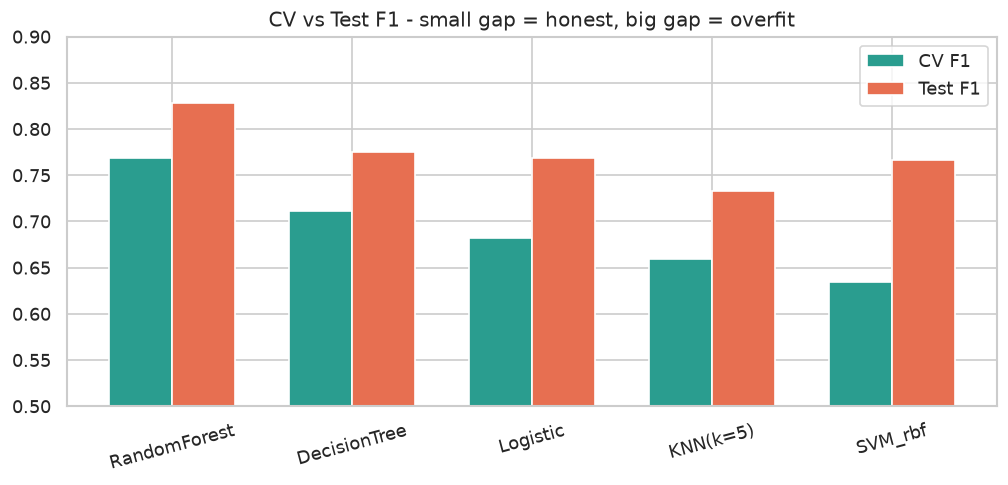

If CV and Test are close, the model is honest. If Test is much lower, it memorized training.


In [ ]:
### Save the comparsion

comp.to_csv('../data/outputs/comparison.csv', index=False)
print("Saved to ../data/outputs/comparison.csv")

# Also show the directness: train vs test gap
plt.figure(figsize=(10,4))
x = comp['model']
width = 0.35

plt.bar([p - width/2 for p in range(len(x))], comp['CV_f1'], width, label='CV F1', color='#2a9d8f')
plt.bar([p + width/2 for p in range(len(x))], comp['test_f1'], width, label='Test F1', color='#e76f51')
plt.xticks(range(len(x)), x, rotation=15)
plt.ylim(0.5,0.9)
plt.legend()
plt.title('CV vs Test F1 - small gap = honest, big gap = overfit')
plt.show()
print("If CV and Test are close, the model is honest. If Test is much lower, it memorized training.")

#### Observation / Conclusion

No single model wins everywhere - Logistic is clear, Tree is explainable, KNN is simple but needs scaling, SVM bends and Random Forest - by averaging many trees - was the most reliable here (CV F1 ~0.77, Test F1 ~0.83). That's why we tried each separately and then lined them up.